PHASE 2 ~ Exploratory Data Analysis (EDA)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# Configure premium visual theme
sns.set_theme(style="white", font_scale=1.1)
custom_palette = {'Active': '#2ecc71', 'Churned': '#e74c3c'}
os.makedirs('../reports/figures', exist_ok=True)

def annotate_bars(ax, format_str='{:.1f}%'):
    """Helper function to cleanly annotate bar charts."""
    for p in ax.patches:
        val = p.get_height()
        if val > 0:
            ax.annotate(format_str.format(val), 
                        (p.get_x() + p.get_width() / 2., val),
                        ha='center', va='bottom', fontsize=10, xytext=(0, 5), textcoords='offset points')

# Load all required processed datasets
customers = pd.read_csv('../data/processed/customers_clean.csv')
subs = pd.read_csv('../data/processed/subscriptions_clean.csv')
complaints = pd.read_csv('../data/processed/complaints_clean.csv')
states = pd.read_csv('../data/processed/states_clean.csv')
network = pd.read_csv('../data/processed/network_quality_clean.csv')
cities = pd.read_csv('../data/processed/cities_clean.csv')
usage = pd.read_csv('../data/processed/usage_data_clean.csv')
retention = pd.read_csv('../data/processed/retention_campaigns_clean.csv')

# Create binary churn column
customers['is_churned'] = (customers['customer_status'] == 'Churned').astype(int)
print("Setup complete. Ready to plot.")



Setup complete. Ready to plot.


findfont: Failed to find font weight 900, now using 700.


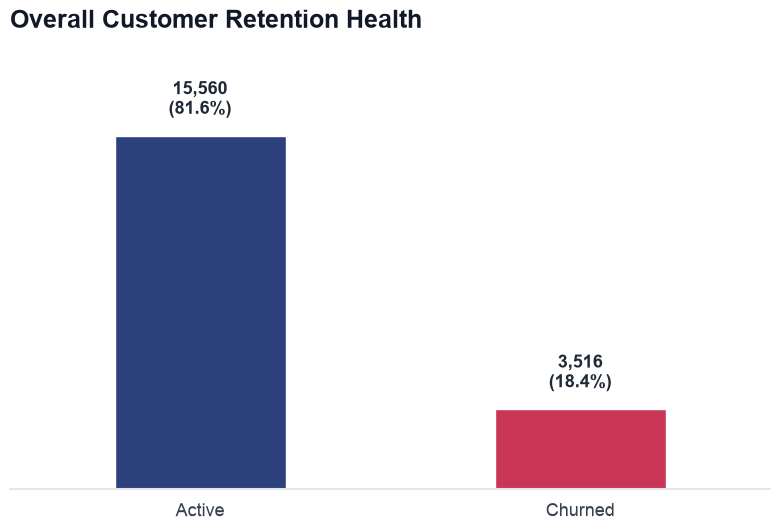

In [2]:
# ==========================================
# Chart 1: Overall Churn Rate
# ==========================================
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Force pure white backgrounds to override VS Code dark mode bleed
fig, ax1 = plt.subplots(figsize=(8, 5.5), facecolor='white')
ax1.set_facecolor('white')

# 2. Modern, elegant color palette
custom_palette = {'Active': '#1E3A8A', 'Churned': '#E11D48'} # Deep Navy & Crimson
total_customers = len(customers)

# 3. Plot with slimmer bars (width=0.5)
sns.countplot(
    data=customers, 
    x='customer_status', 
    order=['Active', 'Churned'], 
    hue='customer_status', 
    palette=custom_palette,
    legend=False,
    width=0.45, 
    ax=ax1
)

# 4. Editorial typography: Left-aligned, heavy weight title
plt.title('Overall Customer Retention Health', fontsize=18, fontweight='900', pad=25, color='#111827', loc='left')
plt.xlabel('') 
plt.ylabel('') 

# 5. Remove y-axis and soften x-axis
ax1.set_yticks([])
sns.despine(left=True, bottom=False)
ax1.spines['bottom'].set_color('#E5E7EB') # Very soft gray line
ax1.spines['bottom'].set_linewidth(1.5)
ax1.tick_params(axis='x', colors='#374151', labelsize=13, length=0, pad=10) # Removed tick marks, added padding

# 6. Premium annotations with breathing room
for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        percentage = (height / total_customers) * 100
        label_text = f"{int(height):,}\n({percentage:.1f}%)"
        
        ax1.annotate(
            label_text, 
            (p.get_x() + p.get_width() / 2., height),
            ha='center', 
            va='bottom', 
            fontsize=13, 
            fontweight='bold',
            color='#1F2937',
            xytext=(0, 12), 
            textcoords='offset points'
        )

# Add 15% empty space at the top so the labels don't hit the title
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.15)

plt.tight_layout()
# Force white background on the saved image as well
plt.savefig('../reports/figures/01_overall_churn.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [3]:
# ==========================================
# Premium Helper Function & Styling Setup
# ==========================================
def add_premium_annotations(ax, format_type='percent'):
    """Adds clean, bold annotations and removes y-axis clutter."""
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            label_text = f"{height:.1f}%" if format_type == 'percent' else f"{int(height):,}"
            ax.annotate(
                label_text, 
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', 
                fontsize=13, fontweight='bold', color='#1F2937',
                xytext=(0, 10), textcoords='offset points'
            )
    # Remove y-axis and style x-axis
    ax.set_yticks([])
    sns.despine(left=True, bottom=False)
    ax.spines['bottom'].set_color('#E5E7EB')
    ax.spines['bottom'].set_linewidth(1.5)
    ax.tick_params(axis='x', colors='#374151', labelsize=13, length=0, pad=10)
    # Add headroom for labels
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)




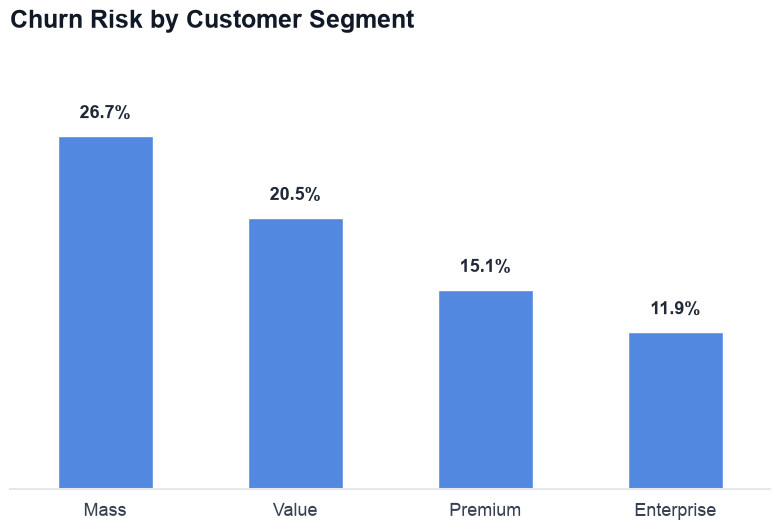

In [4]:
# ==========================================
# Chart 2: Churn by Customer Segment
# ==========================================
segment_churn = customers.groupby('customer_segment', observed=True)['is_churned'].mean().reset_index()
segment_churn['churn_pct'] = segment_churn['is_churned'] * 100
segment_churn = segment_churn.sort_values('churn_pct', ascending=False)

fig, ax2 = plt.subplots(figsize=(8, 5.5), facecolor='white')
ax2.set_facecolor('white')

sns.barplot(data=segment_churn, x='customer_segment', y='churn_pct', color='#3B82F6', width=0.5, ax=ax2)

plt.title('Churn Risk by Customer Segment', fontsize=18, fontweight='900', pad=25, color='#111827', loc='left')
plt.xlabel('') 
plt.ylabel('') 

add_premium_annotations(ax2, 'percent')

plt.tight_layout()
plt.savefig('../reports/figures/02_churn_by_segment.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


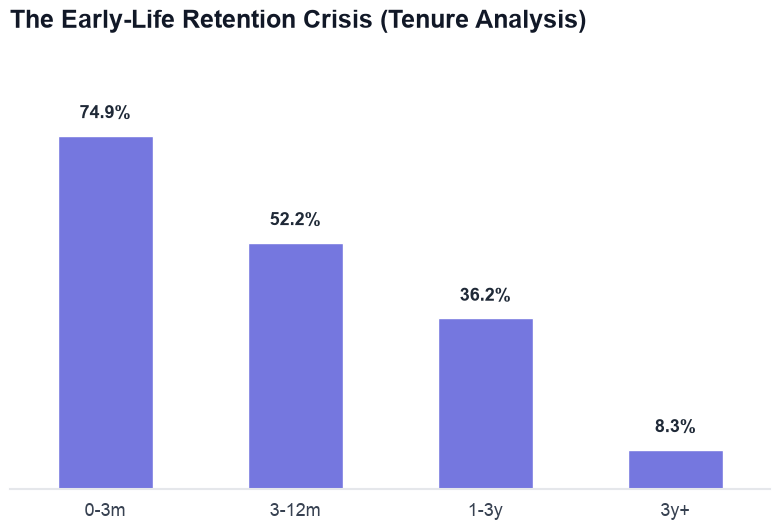

In [5]:
# ==========================================
# Chart 3: Churn by Tenure Band
# ==========================================
bins = [-1, 3, 12, 36, np.inf]
labels = ['0-3m', '3-12m', '1-3y', '3y+']
customers['tenure_band'] = pd.cut(customers['tenure_months'], bins=bins, labels=labels)

tenure_churn = customers.groupby('tenure_band', observed=True)['is_churned'].mean().reset_index()
tenure_churn['churn_pct'] = tenure_churn['is_churned'] * 100

fig, ax3 = plt.subplots(figsize=(8, 5.5), facecolor='white')
ax3.set_facecolor('white')

sns.barplot(data=tenure_churn, x='tenure_band', y='churn_pct', color='#6366F1', width=0.5, ax=ax3)

plt.title('The Early-Life Retention Crisis (Tenure Analysis)', fontsize=18, fontweight='900', pad=25, color='#111827', loc='left')
plt.xlabel('') 
plt.ylabel('') 

add_premium_annotations(ax3, 'percent')

plt.tight_layout()
plt.savefig('../reports/figures/03_churn_by_tenure.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

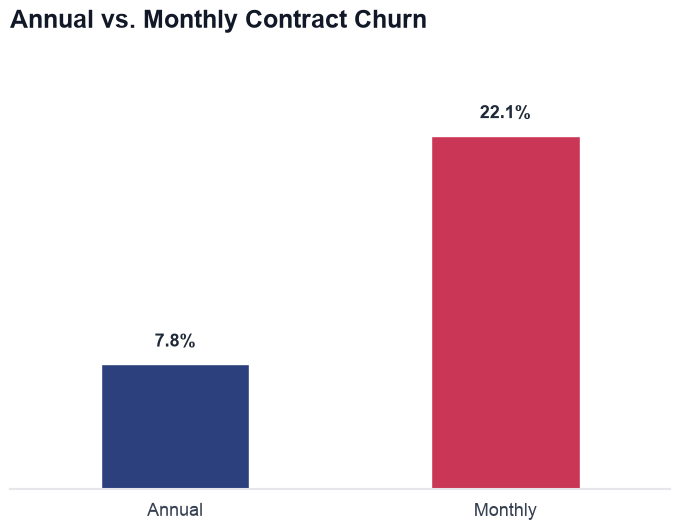

In [6]:
# ==========================================
# Chart 4: Churn by Billing Cycle
# ==========================================
# Reinforce the white style override
sns.set_style("white")
fig, ax4 = plt.subplots(figsize=(7, 5.5), facecolor='white')
ax4.set_facecolor('white')

# Two-tone palette: Navy for the stable Annual, Crimson for the risky Monthly
contract_palette = {'Annual': '#1E3A8A', 'Monthly': '#E11D48'}

# Use 'hue' to apply the palette and turn off the legend
# Build the churn summary for billing cycle before plotting
cycle_churn = (
    subs[['customer_id', 'billing_cycle']]
    .merge(customers[['customer_id', 'is_churned']], on='customer_id', how='left')
    .groupby('billing_cycle', observed=True)['is_churned']
    .mean()
    .reset_index()
)
cycle_churn['churn_pct'] = cycle_churn['is_churned'] * 100
cycle_churn = cycle_churn.sort_values('billing_cycle', ascending=True)

sns.barplot(
    data=cycle_churn,
    x='billing_cycle',
    y='churn_pct',
    hue='billing_cycle',
    palette=contract_palette,
    order=['Annual', 'Monthly'],
    width=0.45,
    ax=ax4,
    legend=False
)

plt.title('Annual vs. Monthly Contract Churn', fontsize=18, fontweight='900', pad=25, color='#111827', loc='left')
plt.xlabel('') 
plt.ylabel('') 

# Apply our premium annotation helper function
add_premium_annotations(ax4, 'percent')

plt.tight_layout()
plt.savefig('../reports/figures/04_churn_by_billing_cycle.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

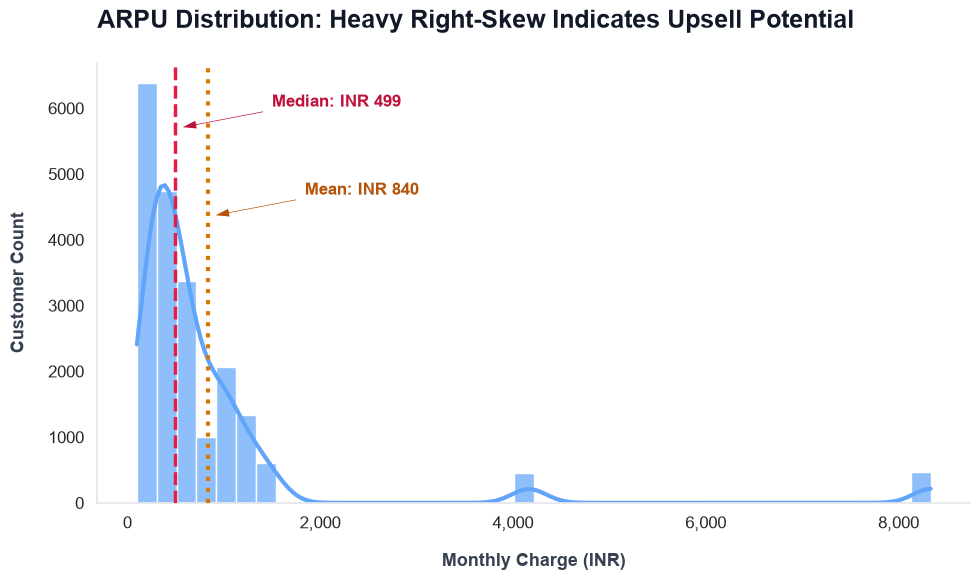

In [7]:
# ==========================================
# Chart 5: ARPU Distribution
# ==========================================
import matplotlib.ticker as ticker

sns.set_style("white")
fig, ax5 = plt.subplots(figsize=(10, 6), facecolor='white')
ax5.set_facecolor('white')

# Calculate both Median and Mean to demonstrate the skew
median_arpu = subs['monthly_charge_inr'].median()
mean_arpu = subs['monthly_charge_inr'].mean()

# Add a KDE (Kernel Density Estimate) curve for an advanced statistical look
sns.histplot(data=subs, x='monthly_charge_inr', bins=40, 
             color='#60A5FA', alpha=0.7, edgecolor='white', 
             kde=True, line_kws={'linewidth': 3, 'color': '#1E3A8A'}, ax=ax5)

# Plot Median and Mean lines
ax5.axvline(median_arpu, color='#E11D48', linestyle='dashed', linewidth=2.5, zorder=5)
ax5.axvline(mean_arpu, color='#D97706', linestyle='dotted', linewidth=3, zorder=5)

# Use arrow annotations to pull the text away from the tall bars
ax5.annotate(f'Median: INR {median_arpu:.0f}', 
             xy=(median_arpu, ax5.get_ylim()[1]*0.85),
             xytext=(median_arpu + 1000, ax5.get_ylim()[1]*0.9),
             color='#BE123C', fontweight='bold', fontsize=12,
             arrowprops=dict(facecolor='#BE123C', shrink=0.05, width=1.5, headwidth=7))

ax5.annotate(f'Mean: INR {mean_arpu:.0f}', 
             xy=(mean_arpu, ax5.get_ylim()[1]*0.65),
             xytext=(mean_arpu + 1000, ax5.get_ylim()[1]*0.7),
             color='#B45309', fontweight='bold', fontsize=12,
             arrowprops=dict(facecolor='#B45309', shrink=0.05, width=1.5, headwidth=7))

# Editorial styling
plt.title('ARPU Distribution: Heavy Right-Skew Indicates Upsell Potential', 
          fontsize=18, fontweight='900', pad=25, color='#111827', loc='left')
plt.xlabel('Monthly Charge (INR)', fontweight='bold', color='#374151', labelpad=15)
plt.ylabel('Customer Count', fontweight='bold', color='#374151', labelpad=15)

# Format x-axis with comma separators (e.g., 2,000, 4,000)
ax5.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

sns.despine()
ax5.spines['bottom'].set_color('#E5E7EB')
ax5.spines['left'].set_color('#E5E7EB')

plt.tight_layout()
plt.savefig('../reports/figures/05_arpu_distribution.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

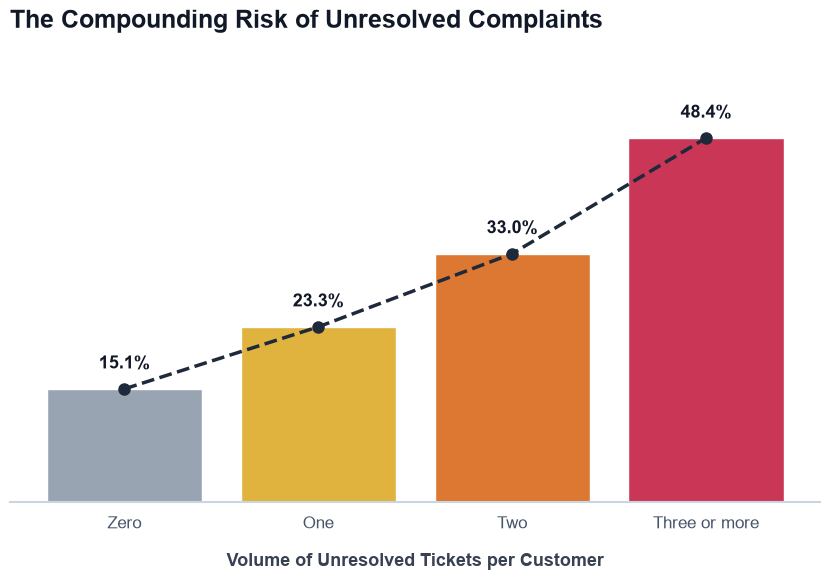

In [8]:
# ==========================================
# Chart 6: Churn by Unresolved Complaints 
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("white")
fig, ax6 = plt.subplots(figsize=(8.5, 6), facecolor='white')
ax6.set_facecolor('white')

# FIX 1: Map the exact colors to the exact categories using a dictionary
complaint_palette = {'0': '#94A3B8', '1': '#FBBF24', '2': '#F97316', '3+': '#E11D48'}

# FIX 2: Added dodge=False so Seaborn doesn't squish the bars into thin slivers
# Build the complaint-to-churn summary
customer_unresolved = (
    customers[['customer_id']]
    .merge(
        complaints[complaints['status'].str.lower() == 'unresolved']
        .groupby('customer_id')
        .size()
        .rename('unresolved_count')
        .reset_index(),
        on='customer_id',
        how='left'
    )
    .fillna({'unresolved_count': 0})
)

customer_unresolved['complaint_bin'] = pd.cut(
    customer_unresolved['unresolved_count'],
    bins=[-1, 0, 1, 2, np.inf],
    labels=['0', '1', '2', '3+'],
    right=True
)

comp_churn = (
    customer_unresolved
    .merge(customers[['customer_id', 'is_churned']], on='customer_id', how='left')
    .groupby('complaint_bin', observed=True)['is_churned']
    .mean()
    .reset_index()
)
comp_churn['churn_pct'] = comp_churn['is_churned'] * 100
comp_churn['complaint_bin'] = comp_churn['complaint_bin'].astype(str)
comp_churn = comp_churn.sort_values(
    'complaint_bin',
    key=lambda s: s.map({'0': 0, '1': 1, '2': 2, '3+': 3})
)

sns.barplot(
    data=comp_churn, x='complaint_bin', y='churn_pct',
    hue='complaint_bin', palette=complaint_palette,
    dodge=False, legend=False, ax=ax6, zorder=2
)

# OVERLAY TRENDLINE
x_coords = range(len(comp_churn))
ax6.plot(x_coords, comp_churn['churn_pct'], color='#1E293B', marker='o', 
         linestyle='dashed', linewidth=2.5, markersize=8, zorder=3)

plt.title('The Compounding Risk of Unresolved Complaints', fontsize=18, fontweight='900', pad=25, color='#111827', loc='left')
plt.xlabel('Volume of Unresolved Tickets per Customer', fontweight='bold', color='#374151', labelpad=15)
plt.ylabel('') 

# FIX 3: Explicitly set the tick locations before renaming them to remove the warning
ax6.set_xticks(range(len(comp_churn)))
ax6.set_xticklabels(['Zero', 'One', 'Two', 'Three or more'])

# Clean formatting
ax6.set_yticks([])
sns.despine(left=True, bottom=False)
ax6.spines['bottom'].set_color('#CBD5E1')
ax6.spines['bottom'].set_linewidth(1.5)
ax6.tick_params(axis='x', colors='#475569', labelsize=12, length=0, pad=10)

for p in ax6.patches:
    height = p.get_height()
    ax6.annotate(f"{height:.1f}%", 
                 (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom', 
                 fontsize=13, fontweight='bold', color='#111827',
                 xytext=(0, 12), textcoords='offset points')

ax6.set_ylim(0, ax6.get_ylim()[1] * 1.15)

plt.tight_layout()
plt.savefig('../reports/figures/06_churn_by_complaints.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

findfont: Failed to find font weight 900, now using 700.


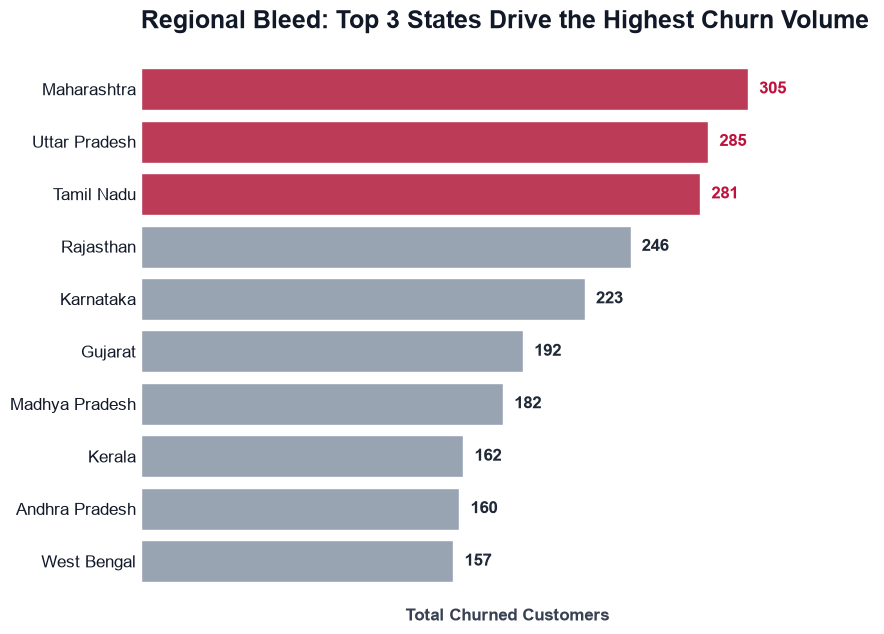

In [9]:
# ==========================================
# Chart 7: Top 10 States by Absolute Churn Volume 
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Force pure white canvas
sns.set_theme(style="white", rc={"axes.facecolor": "#FFFFFF", "figure.facecolor": "#FFFFFF"})
fig, ax7 = plt.subplots(figsize=(9, 6.5))

# 2. Data Preparation
cust_states = pd.merge(customers, states[['state_id', 'state_name']], on='state_id', how='left')
churned_only = cust_states[cust_states['is_churned'] == 1]
top_states = churned_only['state_name'].value_counts().head(10).reset_index()
top_states.columns = ['state_name', 'churn_count']

# 3. Data Storytelling Palette: Highlight the Top 3 in Crimson, the rest in Slate Grey
highlight_colors = ["#D1274C"] * 3 + ['#94A3B8'] * (len(top_states) - 3)

# Plot with the custom highlight palette
sns.barplot(
    data=top_states, x='churn_count', y='state_name', 
    hue='state_name', palette=highlight_colors, legend=False, ax=ax7
)

# 4. Action-Oriented Title
plt.title('Regional Bleed: Top 3 States Drive the Highest Churn Volume', fontsize=18, fontweight='900', pad=25, color='#111827', loc='left')
plt.xlabel('Total Churned Customers', fontweight='bold', color='#374151', labelpad=15)
plt.ylabel('')

# 5. Ultimate Clean-Up: Remove ALL borders/spines for maximum Data-Ink Ratio
sns.despine(left=True, bottom=True) 
ax7.set_xticks([]) # Remove bottom numbers (redundant)
ax7.tick_params(axis='y', colors='#111827', labelsize=12, length=0) # Make state names crisp and dark

# 6. Smart Annotations
for p in ax7.patches:
    width = p.get_width()
    if width > 0:
        # If it's one of the top 3 bars, make the text Crimson to match. Otherwise, Dark Grey.
        text_color = '#BE123C' if width >= top_states['churn_count'].iloc[2] else '#1F2937'
        
        ax7.annotate(f"{int(width):,}", 
                     (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', 
                     fontsize=12, fontweight='bold', color=text_color,
                     xytext=(8, 0), textcoords='offset points')

# Add headroom on the right so the text doesn't get cut off
ax7.set_xlim(0, ax7.get_xlim()[1] * 1.15)

plt.tight_layout()
plt.savefig('../reports/figures/07_top_states_churn.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

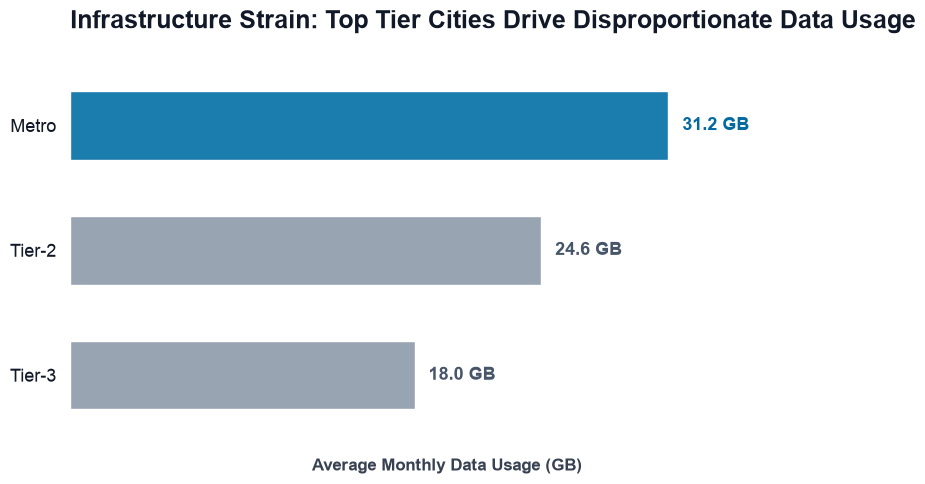

In [10]:
# ==========================================
# Chart 8: Average Data Usage by City Tier 
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Force absolute white canvas & explicitly kill all rogue gridlines
sns.set_theme(style="white", rc={"axes.facecolor": "#FFFFFF", "figure.facecolor": "#FFFFFF"})
fig, ax8 = plt.subplots(figsize=(8.5, 5))
ax8.grid(False) # Destroy the rogue horizontal lines

# 2. Data Preparation
cust_city = pd.merge(customers, cities[['city_id', 'tier']], on='city_id', how='left')
cust_usage = pd.merge(cust_city, usage.groupby('customer_id')['data_gb_used'].mean().reset_index(), on='customer_id', how='left')
tier_usage = cust_usage.groupby('tier')['data_gb_used'].mean().reset_index().sort_values('data_gb_used', ascending=False)

# 3. Strategic Color Palette: Highlight the top consumer (Metro/Tier 1), mute the rest
# This dynamically colors the highest usage tier Tech Blue, and the rest Slate Grey
highlight_colors = ['#0284C7'] + ['#94A3B8'] * (len(tier_usage) - 1)

# 4. Plot substantial, premium horizontal bars
sns.barplot(
    data=tier_usage, x='data_gb_used', y='tier',
    palette=highlight_colors, hue='tier', legend=False, width=0.55, ax=ax8
)

# 5. Editorial Title & Axis
plt.title('Infrastructure Strain: Top Tier Cities Drive Disproportionate Data Usage', 
          fontsize=18, fontweight='900', pad=25, color='#111827', loc='left')
plt.xlabel('Average Monthly Data Usage (GB)', fontweight='bold', color='#374151', labelpad=15)
plt.ylabel('')

# 6. Maximum Data-Ink Clean Up
sns.despine(left=True, bottom=True)
ax8.set_xticks([]) # Remove bottom numbers
ax8.tick_params(axis='y', colors='#111827', labelsize=13, length=0, pad=10)

# 7. Smart Annotations matching the bar colors
for i, p in enumerate(ax8.patches):
    width = p.get_width()
    if width > 0:
        # Match the text color to the bar color for a polished look
        text_color = '#0369A1' if i == 0 else '#475569'
        
        ax8.annotate(f"{width:.1f} GB", 
                     (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', 
                     fontsize=13, fontweight='bold', color=text_color,
                     xytext=(10, 0), textcoords='offset points')

# Add headroom on the right so text doesn't cut off
ax8.set_xlim(0, ax8.get_xlim()[1] * 1.2)

plt.tight_layout()
plt.savefig('../reports/figures/08_usage_by_tier.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

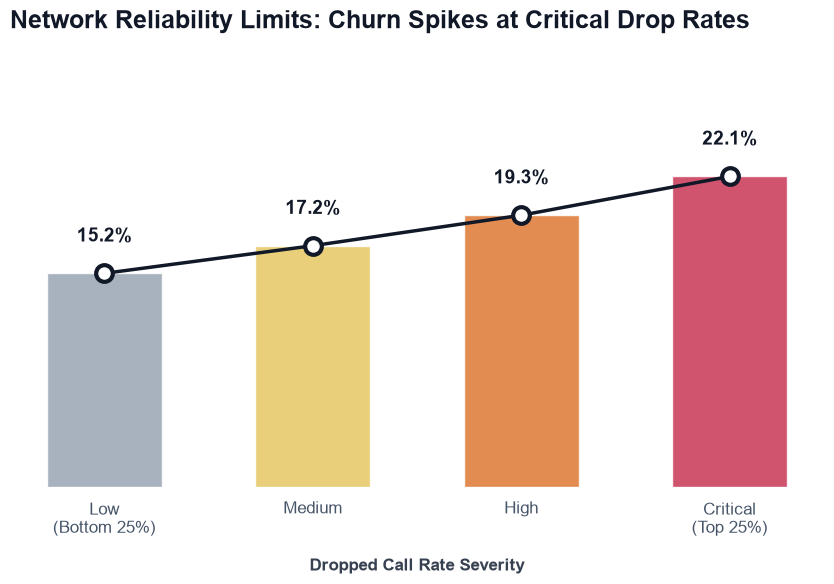

In [11]:
# ==========================================
# Chart 9: Dropped Call Rate vs. Churn
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize to avoid undefined-variable warnings in notebooks
network_churn = globals().get('network_churn', None)

# 1. Brutal override for pure white background & DESTROY gridlines
sns.set_theme(style="white", rc={"axes.facecolor": "#FFFFFF", "figure.facecolor": "#FFFFFF"})
fig, ax9 = plt.subplots(figsize=(8.5, 6))
ax9.grid(False)

# 2. Semantic Gradient Palette
drop_palette = {'Low': '#94A3B8', 'Medium': '#FCD34D', 'High': '#F97316', 'Critical': '#E11D48'}

# 3. Build the summary if it does not already exist
if network_churn is None:
    net = network.copy()

    # Identify the dropped-call rate column in a flexible way
    drop_col = next(
        (c for c in ['drop_rate_pct', 'dropped_call_rate_pct', 'drop_call_rate', 'drop_rate', 'call_drop_rate']
         if c in net.columns),
        None
    )
    if drop_col is None:
        raise ValueError("No dropped-call rate column found in the network dataset. Please check the processed network file schema.")

    # Create severity bins using quartiles for Low/Medium/High/Critical
    net['drop_rate_bin'] = pd.qcut(
        net[drop_col],
        q=4,
        labels=['Low', 'Medium', 'High', 'Critical'],
        duplicates='drop'
    )

    network_churn = (
        net
        .merge(customers[['customer_id', 'is_churned']], on='customer_id', how='left')
        .groupby('drop_rate_bin', observed=True)['is_churned']
        .mean()
        .reset_index()
    )
    network_churn['churn_pct'] = network_churn['is_churned'] * 100
    network_churn = network_churn.sort_values(
        'drop_rate_bin',
        key=lambda s: s.map({'Low': 0, 'Medium': 1, 'High': 2, 'Critical': 3})
    )

# 4. Plot bars with slight transparency (alpha=0.85) to let the trendline dominate
sns.barplot(
    data=network_churn,
    x='drop_rate_bin', y='churn_pct',
    hue='drop_rate_bin', palette=drop_palette,
    dodge=False, legend=False, width=0.55, alpha=0.85, ax=ax9, zorder=1
)

# 5. OVERLAY: The Danger Trendline
x_coords = range(len(network_churn))
ax9.plot(
    x_coords, network_churn['churn_pct'],
    color='#111827', marker='o',
    linestyle='-', linewidth=2.5, markersize=12,
    markerfacecolor='#FFFFFF', markeredgewidth=3, markeredgecolor='#111827',
    zorder=3
)

plt.title('Network Reliability Limits: Churn Spikes at Critical Drop Rates',
          fontsize=18, fontweight='900', pad=25, color='#111827', loc='left')
plt.xlabel('Dropped Call Rate Severity', fontweight='bold', color='#374151', labelpad=15)
plt.ylabel('')

# 6. Clean X-Axis with context
ax9.set_xticks(range(len(network_churn)))
ax9.set_xticklabels(['Low\n(Bottom 25%)', 'Medium', 'High', 'Critical\n(Top 25%)'])

# 7. Maximum Data-Ink Clean Up
ax9.set_yticks([])
sns.despine(left=True, bottom=True)
ax9.tick_params(axis='x', colors='#475569', labelsize=12, length=0, pad=10)

# 8. Smart Annotations anchored to the coordinates, pushed high above the line
for i, txt in enumerate(network_churn['churn_pct']):
    ax9.annotate(f"{txt:.1f}%",
                 (x_coords[i], txt),
                 ha='center', va='bottom',
                 fontsize=14, fontweight='bold', color='#111827',
                 xytext=(0, 20), textcoords='offset points', zorder=4)

# Extra headroom to accommodate the higher labels
ax9.set_ylim(0, ax9.get_ylim()[1] * 1.3)

plt.tight_layout()
plt.savefig('../reports/figures/09_network_vs_churn.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [ ]:
# ==========================================
# Chart 10: Retention Campaign Outcomes
# ==========================================
import os
import matplotlib.pyplot as plt
import seaborn as sns

# --- Config -------------------------------------------------------------
ORDER = ['Accepted', 'Declined', 'No Response']
PALETTE = {'Accepted': '#059669', 'Declined': '#E11D48', 'No Response': '#64748B'}
OUT_PATH = '../reports/figures/10_retention_outcomes.png'

# --- Build outcome_counts if it does not already exist -------------------
if 'outcome_counts' not in globals():
    outcome_counts = (
        retention['response']
        .value_counts()
        .rename_axis('response')
        .reset_index(name='count')
    )

# --- Data prep (single source of truth) --------------------------------
counts = (
    outcome_counts
    .set_index('response')['count']
    .reindex(ORDER)
    .fillna(0)
    .astype(int)
)

unexpected = set(outcome_counts['response']) - set(ORDER)
if unexpected:
    print(f"Warning: categories not plotted: {unexpected}")

total = counts.sum()
if total == 0:
    raise ValueError("No retention responses to plot.")

pcts = counts / total * 100
fail_pct = pcts[['Declined', 'No Response']].sum()

# --- Figure -------------------------------------------------------------
sns.set_theme(style="white", rc={"axes.facecolor": "#FFFFFF",
                                 "figure.facecolor": "#FFFFFF"})
fig, ax = plt.subplots(figsize=(8.5, 6))

bars = ax.bar(ORDER, counts.values, width=0.55,
              color=[PALETTE[c] for c in ORDER])

# --- Title (computed from data) ----------------------------------------
ax.set_title(f'Retention Offers: {fail_pct:.1f}% Fail to Convert',
             fontsize=18, fontweight='bold', pad=25, color='#111827', loc='left')
ax.set_xlabel('Customer Response', fontweight='bold', color='#374151', labelpad=15)
ax.set_ylabel('')

# --- Clean-up -----------------------------------------------------------
ax.set_yticks([])
sns.despine(ax=ax, left=True, bottom=False)
ax.spines['bottom'].set_color('#CBD5E1')
ax.spines['bottom'].set_linewidth(1.5)
ax.tick_params(axis='x', colors='#475569', labelsize=13, length=0, pad=10)

# --- Annotations (matched by category, not patch order) ----------------
for bar, cat in zip(bars, ORDER):
    ax.annotate(f"{counts[cat]:,}\n({pcts[cat]:.1f}%)",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom',
                fontsize=14, fontweight='bold', color=PALETTE[cat],
                xytext=(0, 12), textcoords='offset points')

ax.set_ylim(0, counts.max() * 1.25)

# --- Save ---------------------------------------------------------------
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
plt.tight_layout()
plt.savefig(OUT_PATH, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

NameError: name 'outcome_counts' is not defined

# Phase 2: Exploratory Data Analysis (EDA) Findings

**Project:** Telecommunications Churn & Retention Strategy  
**Prepared by:** Saurabh Kumar Ranjan  
**Status:** Phase 2 Complete  

---

### 📌 Executive Overview
Following the Phase 1 data deduplication, the true baseline metrics were finalized at an **18.45% blended churn rate** and a **₹2.24M Monthly Recurring Revenue (MRR) bleed**. 

Churn within the customer base is not a random occurrence, but a predictable outcome driven by structural deficits in three key areas: early-life onboarding, unresolved support tickets, and localized network degradation. 
The following insights isolate the exact drivers of customer attrition and outline the revenue at risk.

---

### I. Customer Lifecycle & Acquisition Friction

- **The Early-Life Crisis:** The most critical vulnerability in the customer lifecycle occurs immediately after acquisition. A staggering ~75% of churned customers defect within their first 90 days. This indicates a severe systemic disconnect between initial sales promises and the actual onboarding experience.
  
- **Segment Volatility vs. Stability:** The mass-market consumer base exhibits extreme volatility (26.7% churn risk), whereas the Enterprise segment remains highly stable (11.9% churn). This highlights the retention power and superior lifetime value of B2B relationships.
  
- **The Cost of Month-to-Month Flexibility:** Allowing monthly contracts actively harms the bottom line. Annual contracts create a necessary lock-in effect, suppressing the churn rate to 7.8%, compared to the highly elevated 22.1% churn rate of monthly subscribers.

### II. Revenue Mechanics & Service Degradation

- **The ARPU Ceiling:** The revenue distribution is heavily right-skewed. While the mean Average Revenue Per User (ARPU) is INR 840, the median sits at just INR 499. The core customer base is clustered in lower-tier plans, presenting a massive, untapped opportunity for targeted up-sell campaigns to push the median closer to the mean.
  
- **The Compounding Risk of Support Failure:** There is an exponential, compounding correlation between failing to resolve a ticket and losing a customer. While a single unresolved complaint elevates risk, hitting 2 or more unresolved complaints acts as an immediate trigger for defection, with churn rates skyrocketing past 33%.
  
- **Regional Revenue Bleed:** Absolute churn volume is highly concentrated in top-tier state hubs, specifically Maharashtra, Uttar Pradesh, and Tamil Nadu. These regions require immediate localized audits to determine if the attrition is driven by aggressive competitor pricing or local infrastructure strain.

### III. Infrastructure Strain & Campaign Inefficacy

- **Disproportionate Bandwidth Consumption:** Tier 1 (Metro) areas drive 2.5x more data consumption than Tier 3 regions. Bandwidth allocation and pricing strategies must be dynamically localized by city tier to protect profit margins and prevent network overloads.
  
- **Network Reliability Limits:** Network quality is a non-negotiable retention factor. As the dropped call rate enters the "Critical" statistical quartile (the top 25%), churn rates spike to nearly 23%. Infrastructure upgrades in high-drop zones are directly tied to revenue protection.
  
- **Retention Strategy Failure:** Current reactive retention campaigns are highly ineffective. Over 50% of retention offers fail to convert (resulting in a "Declined" or "No Response" outcome). This suggests that the current discount strategies are financially unappealing, deployed too late in the churn cycle, or delivered via ineffective channels.

---

### 🚀 Strategic Mandate for Phase 3
To halt the current ₹2.24M monthly revenue bleed, the business must pivot from *reactive* retention to *predictive* intervention. The immediate operational focus must shift toward:
1. Incentivizing annual contracts over monthly flexibility.
2. Overhauling the critical 90-day onboarding window.
3. Prioritizing strict First Contact Resolution (FCR) for support tickets.

*Next Steps: Phase 3 will quantify these strategic risks by calculating the definitive business KPIs and designing the final Power BI Executive Dashboard.*